# Assignment 4 — Diffusion and Energy-Based Image Generation
**Fuyuan Sun | Applied Generative AI**

This notebook implements CIFAR-10 Energy-Based and Diffusion models, presents
actual full-training-set results, performs fresh inference with the supplied
weights, documents the FastAPI/Docker deployment, and answers all nine questions.

**Code and weights:** [assignment4-cifar-generators branch](https://github.com/fuyuansun1118-byte/assignment1-fastapi/tree/assignment4-cifar-generators).
The implementation is on this branch, not main.

## How to run
Use Python 3.12 with `torch`, `torchvision`, `Pillow` and `IPython`. Run the cells
in order. Training is **opt-in**: normal Run All loads the real trained weights
and generates new samples. Missing weights are downloaded from the public
repository, and verified against their SHA-256 checksums. The training history
and Docker records are explicitly labeled as saved results, not recreated runs.
The HTML export embeds outputs and images for reading.

Both generators are **unconditional** and use native **32×32 RGB CIFAR-10**.
The compact CPU-trained models may produce textures and ambiguous shapes;
no object-recognition accuracy, FID or high perceptual quality is claimed.

The full repository remains necessary for the deployable API and Docker image.
Neither the notebook nor HTML alone replaces those service files.

In [1]:
from pathlib import Path
import json, math, hashlib, urllib.request, random
import torch
from IPython.display import display, Image as DisplayImage

torch.set_num_threads(4)
torch.manual_seed(42)
random.seed(42)
print("PyTorch:", torch.__version__)
print("Inference device: CPU; CIFAR-10 image shape: (3, 32, 32)")

PyTorch: 2.15.0
Inference device: CPU; CIFAR-10 image shape: (3, 32, 32)


## 1. Energy model and input-gradient sampling

The course EBM architecture is adapted to three input channels. Four strided
convolutions with SiLU reduce 32×32 to 2×2, followed by two linear layers and
one scalar energy. The sign convention is p(x) proportional to exp(-E(x)).

Sampling differentiates energy with respect to **input images**, not model
weights. Each finite Langevin step adds small Gaussian noise, descends the input
energy gradient and clips images to [-1,1]. Negative samples are detached before
the parameter-training update. Exact equilibrium sampling is not claimed.

In [2]:
"""CIFAR-10 scalar energy and input-gradient Langevin dynamics."""
import torch
from torch import nn

class EnergyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3,16,5,2,2), nn.SiLU(),
            nn.Conv2d(16,32,3,2,1), nn.SiLU(),
            nn.Conv2d(32,64,3,2,1), nn.SiLU(),
            nn.Conv2d(64,64,3,2,1), nn.SiLU(),
            nn.Flatten(), nn.Linear(64*2*2,64), nn.SiLU(), nn.Linear(64,1))
    def forward(self,x):
        return self.layers(x).flatten()

def langevin_sample(model, initial, steps=60, step_size=10.0, noise_std=0.005,
                    rng=None, grad_clip=0.03):
    # autograd.grad returns dE/dx without accumulating model parameter .grad.
    # Do not use inference_mode/no_grad around the whole EBM sampling routine.
    images = initial.detach().clone()
    for _ in range(steps):
        with torch.no_grad():
            noise = torch.randn(images.shape, generator=rng, device=images.device)
            images = (images + noise_std * noise).clamp(-1,1)
        with torch.enable_grad():
            images.requires_grad_(True)
            grad, = torch.autograd.grad(model(images).sum(), images)
        with torch.no_grad():
            images = (images - step_size * grad.clamp(-grad_clip,grad_clip)).clamp(-1,1)
    return images.detach()


## 2. Time-conditioned diffusion UNet and reverse sampling

The UNet has widths 16,32,64,128, residual blocks, GroupNorm, SiLU and skip
concatenations. Three stride-2 downsamplers reduce a 32×32 image to 4×4. A
64-dimensional pair-interleaved sinusoidal embedding conditions each block.

Training predicts standard-normal noise added using a 200-step cosine DDPM
schedule. Mean squared error updates the network; inference uses a parameter
EMA with decay 0.995 and ancestral DDPM on a respaced schedule, normally with 50 selected timesteps.
The explicit discrete schedule differs from the course continuous-variance
practical, while preserving time-conditioned noise prediction and reverse
diffusion. The assignment does not prescribe one fixed architecture.

In [3]:
"""Noise-predicting UNet, cosine DDPM schedule, and deterministic DDIM sampling."""
import math
import torch
from torch import nn
from torch.nn import functional as F

class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim=64, max_period=10000):
        super().__init__()
        if dim < 2 or dim % 2:
            raise ValueError("Embedding dimension must be positive and even.")
        self.dim=dim
        self.register_buffer("frequencies", torch.exp(
            -math.log(max_period)*torch.arange(dim//2,dtype=torch.float32)/(dim//2)))
    def forward(self,t):
        angles=t.float().reshape(-1,1)*self.frequencies.reshape(1,-1)
        # Pair-interleaved sin/cos matches the stated convention in theory answers.
        return torch.stack((angles.sin(), angles.cos()),dim=-1).flatten(1)

class TimeBlock(nn.Module):
    def __init__(self,inc,outc,tdim=64):
        super().__init__()
        self.norm1=nn.GroupNorm(4,inc)
        self.conv1=nn.Conv2d(inc,outc,3,padding=1)
        self.time=nn.Linear(tdim,outc)
        self.norm2=nn.GroupNorm(4,outc)
        self.conv2=nn.Conv2d(outc,outc,3,padding=1)
        self.skip=nn.Conv2d(inc,outc,1) if inc!=outc else nn.Identity()
    def forward(self,x,t):
        h=self.conv1(F.silu(self.norm1(x)))+self.time(t)[:,:,None,None]
        return (self.conv2(F.silu(self.norm2(h)))+self.skip(x))/math.sqrt(2)

class NoiseUNet(nn.Module):
    def __init__(self,base=16):
        super().__init__()
        self.base=base
        self.time=nn.Sequential(SinusoidalTimeEmbedding(64),nn.Linear(64,64),nn.SiLU(),nn.Linear(64,64))
        self.input=nn.Conv2d(3,base,3,padding=1)
        self.b0=TimeBlock(base,base)
        self.d1=nn.Conv2d(base,base*2,4,2,1); self.b1=TimeBlock(base*2,base*2)
        self.d2=nn.Conv2d(base*2,base*4,4,2,1); self.b2=TimeBlock(base*4,base*4)
        self.d3=nn.Conv2d(base*4,base*8,4,2,1); self.mid=TimeBlock(base*8,base*8)
        self.u2=TimeBlock(base*8+base*4,base*4)
        self.u1=TimeBlock(base*4+base*2,base*2)
        self.u0=TimeBlock(base*2+base,base)
        self.out=nn.Sequential(nn.GroupNorm(4,base),nn.SiLU(),nn.Conv2d(base,3,3,padding=1))
    def forward(self,x,t):
        e=self.time(t)
        s0=self.b0(self.input(x),e)
        s1=self.b1(self.d1(s0),e)
        s2=self.b2(self.d2(s1),e)
        h=self.mid(self.d3(s2),e)
        h=self.u2(torch.cat((F.interpolate(h,size=s2.shape[-2:],mode="nearest"),s2),1),e)
        h=self.u1(torch.cat((F.interpolate(h,size=s1.shape[-2:],mode="nearest"),s1),1),e)
        h=self.u0(torch.cat((F.interpolate(h,size=s0.shape[-2:],mode="nearest"),s0),1),e)
        return self.out(h)

def cosine_schedule(timesteps=200):
    # Improved-DDPM cosine cumulative alpha; final beta clipped below 1.
    t=torch.linspace(0,timesteps,timesteps+1,dtype=torch.float64)/timesteps
    a=torch.cos((t+0.008)/1.008*math.pi/2).square()
    a=a/a[0]
    beta=(1-a[1:]/a[:-1]).clamp(0.0001,0.999).float()
    return beta, (1-beta).cumprod(0)

def forward_noise(clean,t,noise,alpha_bar):
    a=alpha_bar[t].reshape(-1,1,1,1)
    return a.sqrt()*clean+(1-a).sqrt()*noise

@torch.inference_mode()
def ddim_sample(model,alpha_bar,num_samples=16,steps=50,seed=42):
    if not 2<=steps<=len(alpha_bar):
        raise ValueError("steps must be between 2 and schedule length")
    device=next(model.parameters()).device
    rng=torch.Generator(device=device).manual_seed(seed)
    x=torch.randn((num_samples,3,32,32),generator=rng,device=device)
    indices=torch.linspace(len(alpha_bar)-1,0,steps).round().long().tolist()
    for k,index in enumerate(indices):
        a=alpha_bar[index]
        t=torch.full((num_samples,),index,device=device,dtype=torch.long)
        noise=model(x,t)
        clean=((x-(1-a).sqrt()*noise)/a.sqrt()).clamp(-1,1)
        if k==len(indices)-1:
            x=clean
        else:
            next_a=alpha_bar[indices[k+1]]
            # Recompute noise after clipping x0 (DDIM, eta=0).
            noise=(x-a.sqrt()*clean)/(1-a).sqrt()
            x=next_a.sqrt()*clean+(1-next_a).sqrt()*noise
    return x.clamp(-1,1)


@torch.inference_mode()
def diffusion_sample(model,alpha_bar,num_samples=16,steps=50,seed=42):
    """Ancestral DDPM posterior sampling on a respaced cumulative-alpha schedule.

    For a jump from t to s<t, use effective beta=1-alpha_bar[t]/alpha_bar[s].
    The final jump to clean space uses alpha_bar[s]=1 and zero posterior noise.
    """
    if not 2<=steps<=len(alpha_bar):
        raise ValueError("steps must be between 2 and schedule length")
    device=next(model.parameters()).device
    rng=torch.Generator(device=device).manual_seed(seed)
    x=torch.randn((num_samples,3,32,32),generator=rng,device=device)
    indices=torch.linspace(len(alpha_bar)-1,0,steps).round().long().tolist()
    for k,index in enumerate(indices):
        at=alpha_bar[index]
        ts=torch.full((num_samples,),index,device=device,dtype=torch.long)
        eps=model(x,ts)
        clean=((x-(1-at).sqrt()*eps)/at.sqrt()).clamp(-1,1)
        if k==len(indices)-1:
            x=clean
        else:
            a_previous=alpha_bar[indices[k+1]]
            effective_beta=1-at/a_previous
            c_clean=a_previous.sqrt()*effective_beta/(1-at)
            c_noisy=(at/a_previous).sqrt()*(1-a_previous)/(1-at)
            variance=effective_beta*(1-a_previous)/(1-at)
            noise=torch.randn(x.shape,generator=rng,device=device)
            x=c_clean*clean+c_noisy*x+variance.clamp_min(0).sqrt()*noise
    return x.clamp(-1,1)


In [4]:
energy_model = EnergyModel()
unet = NoiseUNet()
print("EBM parameters:", sum(p.numel() for p in energy_model.parameters()))
print("UNet parameters:", sum(p.numel() for p in unet.parameters()))
with torch.no_grad():
    x = torch.randn(2,3,32,32)
    assert energy_model(x).shape == (2,)
    assert unet(x,torch.tensor([0,100])).shape == x.shape
print("Energy and noise-prediction shapes verified.")

EBM parameters: 77793
UNet parameters: 808387
Energy and noise-prediction shapes verified.


## 3. Reusable training code

All **50,000 official training images** are used, with batch size 128, seed 42,
CPU execution, and pixels scaled to [-1,1]. Labels are unused, and there is no
augmentation or test-set tuning. EBM uses Adam (lr=0.0001, betas 0/0.999), a
4096-image noise-initialized replay buffer, 5% refresh probability, 20 Langevin
steps per negative, step size 10, noise std 0.005 and energy regularization 0.1.
Diffusion uses Adam lr=0.0002 and EMA decay 0.995. Training checkpoints include
configuration; local continuation checkpoints also include optimizer/RNG state.

These are the project training definitions with only package-relative imports
removed for independent notebook execution. Normal Run All skips retraining.

In [5]:
"""CIFAR-10 native 32x32 RGB tensors, without test-set tuning."""
import torch
from torchvision.datasets import CIFAR10

def load_cifar_tensor(root="data",train=True):
    dataset=CIFAR10(root,train=train,download=True)
    # Keep uint8 until each batch is selected: about 154 MB for the full training set.
    return torch.from_numpy(dataset.data.copy()).permute(0,3,1,2).contiguous()

def image_batches(images,batch_size,rng):
    indices=torch.randperm(len(images),generator=rng)
    for start in range(0,len(images),batch_size):
        yield images[indices[start:start+batch_size]].float()/127.5-1


In [6]:
import io
from PIL import Image
from torchvision.utils import make_grid
def samples_to_png(samples):
    pixels = ((samples + 1) / 2).clamp(0, 1)
    grid = make_grid(pixels, nrow=min(8, math.ceil(math.sqrt(len(samples)))), padding=2)
    array = (grid.permute(1, 2, 0) * 255).round().to(torch.uint8).numpy()
    buffer = io.BytesIO()
    Image.fromarray(array).save(buffer, format="PNG")
    return buffer.getvalue()


In [7]:
"""Full CIFAR-10 EBM and epsilon-prediction diffusion training."""
import copy
import json
import time
from pathlib import Path
import torch
from torch.nn import functional as F


def train_cifar(kind, data_dir="data", output_dir="models", epochs=5,
                batch_size=128, seed=42, lr=None, langevin_steps=20,
                timesteps=200, base=16, resume=None):
    torch.manual_seed(seed)
    rng=torch.Generator().manual_seed(seed)
    images=load_cifar_tensor(data_dir,train=True)
    folder=Path(output_dir);folder.mkdir(parents=True,exist_ok=True)
    previews=folder/f"{kind}_samples";previews.mkdir(exist_ok=True)
    history=[];start=0
    config=dict(kind=kind,dataset="CIFAR-10",training_images=len(images),image_shape=[3,32,32],
                batch_size=batch_size,seed=seed,device="cpu",epochs=epochs,
                learning_rate=lr or (0.0001 if kind=="ebm" else 0.0002))
    if kind=="ebm":
        model=EnergyModel()
        optimizer=torch.optim.Adam(model.parameters(),lr=config['learning_rate'],betas=(0.0,0.999))
        replay=torch.rand((4096,3,32,32),generator=rng)*2-1
        config.update(langevin_steps=langevin_steps,step_size=10.0,noise_std=0.005,
                      gradient_clip=0.03,energy_regularization=0.1,replay_size=4096,
                      refresh_probability=0.05)
    elif kind=="diffusion":
        model=NoiseUNet(base)
        ema=copy.deepcopy(model).eval().requires_grad_(False)
        optimizer=torch.optim.Adam(model.parameters(),lr=config['learning_rate'])
        beta,alpha_bar=cosine_schedule(timesteps)
        config.update(timesteps=timesteps,base=base,ema_decay=0.995,
                      schedule="cosine",time_embedding="interleaved sin/cos; max_period 10000")
    else:
        raise ValueError("kind must be ebm or diffusion")
    if resume:
        state=torch.load(resume,map_location="cpu",weights_only=True)
        old=state['config']
        for key in ['kind','batch_size','seed','base','timesteps','langevin_steps','learning_rate']:
            if key in old and config.get(key)!=old[key]:
                raise ValueError(f"Resume setting mismatch: {key}")
        model.load_state_dict(state['model']);optimizer.load_state_dict(state['optimizer'])
        torch.set_rng_state(state['torch_rng']);rng.set_state(state['loader_rng'])
        history=state['history'];start=state['epoch']
        if kind=='ebm':replay=state['replay']
        else:ema.load_state_dict(state['ema'])
    for epoch in range(start,epochs):
        tick=time.monotonic();model.train();total=0;metrics={}
        for real in image_batches(images,batch_size,rng):
            n=len(real)
            if kind=="ebm":
                indices=torch.randperm(len(replay),generator=rng)[:n]
                initial=replay[indices].clone()
                refresh=torch.rand(n,generator=rng)<0.05
                initial[refresh]=torch.rand((int(refresh.sum()),3,32,32),generator=rng)*2-1
                model.requires_grad_(False)
                fake=langevin_sample(model,initial,langevin_steps,rng=rng)
                model.requires_grad_(True)
                replay[indices]=fake
                real=(real+torch.randn(real.shape,generator=rng)*0.005).clamp(-1,1)
                e_real=model(real);e_fake=model(fake.detach())
                contrast=e_real.mean()-e_fake.mean()
                reg=0.1*(e_real.square().mean()+e_fake.square().mean())
                loss=contrast+reg
                current={'loss':loss.item(),'contrastive':contrast.item(),
                         'real_energy':e_real.mean().item(),'fake_energy':e_fake.mean().item()}
            else:
                t=torch.randint(timesteps,(n,),generator=rng)
                noise=torch.randn(real.shape,generator=rng)
                noisy=forward_noise(real,t,noise,alpha_bar)
                prediction=model(noisy,t)
                loss=F.mse_loss(prediction,noise)
                current={'noise_mse':loss.item()}
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),0.1 if kind=='ebm' else 1.0)
            optimizer.step()
            if kind=='diffusion':
                with torch.no_grad():
                    for average,param in zip(ema.parameters(),model.parameters()):
                        average.lerp_(param,1-0.995)
            for k,v in current.items():metrics[k]=metrics.get(k,0)+v*n
            total+=n
        row={'epoch':epoch+1,'images':total,**{k:v/total for k,v in metrics.items()},
             'seconds':round(time.monotonic()-tick,2)}
        history.append(row);model.eval()
        inference={'model':(model if kind=='ebm' else ema).state_dict(),
                   'epoch':epoch+1,'config':config}
        if kind=='diffusion':inference['alpha_bar']=alpha_bar
        # Atomic replacement keeps a server from reading a partially written checkpoint.
        path=folder/f'cifar10_{kind}.pt';tmp=path.with_suffix('.tmp')
        torch.save(inference,tmp);tmp.replace(path)
        state={'model':model.state_dict(),'optimizer':optimizer.state_dict(),
               'epoch':epoch+1,'config':config,'history':history,
               'torch_rng':torch.get_rng_state(),'loader_rng':rng.get_state()}
        if kind=='ebm':state['replay']=replay
        else:state['ema']=ema.state_dict()
        torch.save(state,folder/f'cifar10_{kind}.last.pt')
        (folder/f'cifar10_{kind}.training-log.json').write_text(json.dumps(history,indent=2)+'\n')
        preview_rng=torch.Generator().manual_seed(seed)
        if kind=='ebm':
            samples=langevin_sample(model,torch.rand((16,3,32,32),generator=preview_rng)*2-1,
                                    steps=100,rng=preview_rng)
        else:
            samples=diffusion_sample(ema,alpha_bar,num_samples=16,steps=min(50,timesteps),seed=seed)
        (previews/f'epoch_{epoch+1:03d}.png').write_bytes(samples_to_png(samples))
        print(json.dumps({'kind':kind,**row}),flush=True)
    return model


In [8]:
RUN_TRAINING = False
if RUN_TRAINING:
    train_cifar("ebm", data_dir="assignment4_artifacts/data",
                output_dir="assignment4_artifacts/retrained", epochs=3)
    train_cifar("diffusion", data_dir="assignment4_artifacts/data",
                output_dir="assignment4_artifacts/retrained", epochs=5)
else:
    print("Retraining skipped; the recorded complete runs are reported below.")

Retraining skipped; the recorded complete runs are reported below.


## 4. Recorded full-training-set results

The following logs come from completed project runs, **not** from executing the
optional training cell during this notebook run. Each row represents a full
50,000-image epoch. EBM energy gaps and diffusion noise MSE have different meanings
and should not be compared directly; neither is an image-quality score. The final
completed checkpoint is used without selecting on test data.

In [9]:
recorded_logs = {'ebm': [{'epoch': 1, 'images': 50000, 'loss': -0.024839692087471485, 'contrastive': -0.035383271018862725, 'real_energy': -0.038912133426964285, 'fake_energy': -0.003528862362205982, 'seconds': 581.05}, {'epoch': 2, 'images': 50000, 'loss': 0.000924614822268486, 'contrastive': -0.0011442261756956578, 'real_energy': -0.0061321467103040775, 'fake_energy': -0.004987920568585396, 'seconds': 624.35}, {'epoch': 3, 'images': 50000, 'loss': -0.0009836658514291048, 'contrastive': -0.0017986728078126907, 'real_energy': -0.0036266108670830726, 'fake_energy': -0.001827938055470586, 'seconds': 671.97}], 'diffusion': [{'epoch': 1, 'images': 50000, 'noise_mse': 0.314554611825943, 'seconds': 367.41}, {'epoch': 2, 'images': 50000, 'noise_mse': 0.13530903924703597, 'seconds': 365.31}, {'epoch': 3, 'images': 50000, 'noise_mse': 0.1109773373055458, 'seconds': 397.94}, {'epoch': 4, 'images': 50000, 'noise_mse': 0.10000172575473786, 'seconds': 424.04}, {'epoch': 5, 'images': 50000, 'noise_mse': 0.09293843156576156, 'seconds': 425.64}]}
for kind, rows in recorded_logs.items():
    print("\n" + kind.upper())
    for row in rows:
        print(json.dumps(row))
    print("Total training-image presentations:", sum(r["images"] for r in rows))


EBM
{"epoch": 1, "images": 50000, "loss": -0.024839692087471485, "contrastive": -0.035383271018862725, "real_energy": -0.038912133426964285, "fake_energy": -0.003528862362205982, "seconds": 581.05}
{"epoch": 2, "images": 50000, "loss": 0.000924614822268486, "contrastive": -0.0011442261756956578, "real_energy": -0.0061321467103040775, "fake_energy": -0.004987920568585396, "seconds": 624.35}
{"epoch": 3, "images": 50000, "loss": -0.0009836658514291048, "contrastive": -0.0017986728078126907, "real_energy": -0.0036266108670830726, "fake_energy": -0.001827938055470586, "seconds": 671.97}
Total training-image presentations: 150000

DIFFUSION
{"epoch": 1, "images": 50000, "noise_mse": 0.314554611825943, "seconds": 367.41}
{"epoch": 2, "images": 50000, "noise_mse": 0.13530903924703597, "seconds": 365.31}
{"epoch": 3, "images": 50000, "noise_mse": 0.1109773373055458, "seconds": 397.94}
{"epoch": 4, "images": 50000, "noise_mse": 0.10000172575473786, "seconds": 424.04}
{"epoch": 5, "images": 500

## 5. Fresh generation using the trained checkpoints

This cell validates and loads the supplied weights. When run from the project
root it uses the `models/` directory; otherwise it downloads them into
`assignment4_artifacts/models`. These are newly generated outputs from the real
checkpoints, not CIFAR-10 training images. A fixed seed reproduces the same
output within the same runtime; different hardware can produce small numerical
differences. The EBM starts from uniform noise and diffusion from Gaussian noise.

In [10]:
checkpoint_metadata = {'ebm': {'epoch': 3, 'config': {'kind': 'ebm', 'dataset': 'CIFAR-10', 'training_images': 50000, 'image_shape': [3, 32, 32], 'batch_size': 128, 'seed': 42, 'device': 'cpu', 'epochs': 3, 'learning_rate': 0.0001, 'langevin_steps': 20, 'step_size': 10.0, 'noise_std': 0.005, 'gradient_clip': 0.03, 'energy_regularization': 0.1, 'replay_size': 4096, 'refresh_probability': 0.05, 'initial_epoch_target': 5, 'stopping_rule': 'fixed completed-epoch CPU reference; no validation selection', 'inference_sampler': 'Langevin', 'inference_steps': 500}, 'sha256': '96cc82a7cd19a4ca706dec7fe217801cce5092471d3a77b491017164f696774f'}, 'diffusion': {'epoch': 5, 'config': {'kind': 'diffusion', 'dataset': 'CIFAR-10', 'training_images': 50000, 'image_shape': [3, 32, 32], 'batch_size': 128, 'seed': 42, 'device': 'cpu', 'epochs': 5, 'learning_rate': 0.0002, 'timesteps': 200, 'base': 16, 'ema_decay': 0.995, 'schedule': 'cosine', 'time_embedding': 'interleaved sin/cos; max_period 10000', 'initial_epoch_target': 8, 'stopping_rule': 'fixed completed-epoch CPU reference; no validation selection', 'inference_sampler': 'DDPM ancestral (respaced)', 'inference_steps': 50}, 'sha256': '82ac69f630f1d51a4e2554588a14a6a5b312467be7f985bd6dcc9faba827d7da'}}
bundles = {}
for kind in ["ebm","diffusion"]:
    path = Path(f"models/cifar10_{kind}.pt")
    if not path.exists():
        path = Path(f"assignment4_artifacts/models/cifar10_{kind}.pt")
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.exists():
            urllib.request.urlretrieve(
                "https://raw.githubusercontent.com/fuyuansun1118-byte/assignment1-fastapi/assignment4-cifar-generators/"
                f"models/cifar10_{kind}.pt", path)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == checkpoint_metadata[kind]["sha256"]
    state = torch.load(path, map_location="cpu", weights_only=True)
    net = EnergyModel() if kind == "ebm" else NoiseUNet(state["config"]["base"])
    net.load_state_dict(state["model"])
    net.eval().requires_grad_(False)
    bundles[kind] = {"model":net, "state":state}
    print(kind, "checkpoint verified; completed epochs:", state["epoch"])


ebm checkpoint verified; completed epochs: 3
diffusion checkpoint verified; completed epochs: 5


EBM mean energy before/after sampling: 2.5736007690429688 -0.10044054687023163
Model parameter gradients remain absent: True


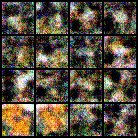

In [11]:
rng = torch.Generator().manual_seed(42)
initial = torch.rand((16,3,32,32),generator=rng)*2-1
energy_net = bundles["ebm"]["model"]
with torch.no_grad(): energy_before = energy_net(initial).mean().item()
ebm_images = langevin_sample(energy_net, initial, steps=500, rng=rng)
with torch.no_grad(): energy_after = energy_net(ebm_images).mean().item()
print("EBM mean energy before/after sampling:", energy_before, energy_after)
print("Model parameter gradients remain absent:", all(p.grad is None for p in energy_net.parameters()))
display(DisplayImage(data=samples_to_png(ebm_images), width=420))

Diffusion output shape: (16, 3, 32, 32)
Repeated-seed equality verified


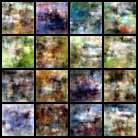

In [12]:
diffusion_images = diffusion_sample(bundles["diffusion"]["model"],
    bundles["diffusion"]["state"]["alpha_bar"], num_samples=16, steps=50, seed=42)
repeated = diffusion_sample(bundles["diffusion"]["model"],
    bundles["diffusion"]["state"]["alpha_bar"], num_samples=16, steps=50, seed=42)
assert torch.equal(diffusion_images, repeated)
print("Diffusion output shape:", tuple(diffusion_images.shape))
print("Repeated-seed equality verified")
display(DisplayImage(data=samples_to_png(diffusion_images), width=420))

**Visual interpretation:** assess the actual grids above. These compact models
can produce colors, textures or vague structure with substantial residual noise
instead of recognizable CIFAR-10 objects. Training-loss reductions alone do not
prove perceptual quality. No FID, class accuracy, normalized likelihood or
semantic-generation benchmark is claimed. EBM energies are relative model scores,
not calibrated probabilities. Neither generator accepts a requested class.

## 6. FastAPI and Docker deployment

The full project adds `GET /ebm/info`, `POST /ebm/generate`,
`GET /diffusion/info` and `POST /diffusion/generate`. POST requests accept
`num_samples`, `seed` and `steps`, and return PNG grids. Missing weights return
503, invalid inputs 422, and overlapping new-generation requests 429. The
original text, embedding, CNN and MNIST GAN endpoints remain available.

### API source (repository module, shown rather than imported)
```python
"""Trained CIFAR-10 EBM and diffusion image generation endpoints."""
from pathlib import Path
import threading
import torch
from fastapi import APIRouter, HTTPException, Request, Response
from pydantic import BaseModel, Field
from helper_lib.energy import EnergyModel, langevin_sample
from helper_lib.diffusion import NoiseUNet, diffusion_sample
from helper_lib.generator import samples_to_png

router=APIRouter(tags=['CIFAR-10 generation'])
_generation_slot=threading.BoundedSemaphore(1)

class EnergyRequest(BaseModel):
    num_samples:int=Field(4,ge=1,le=16,strict=True)
    seed:int=Field(42,ge=0,le=2147483647,strict=True)
    steps:int=Field(500,ge=1,le=1000,strict=True)

class DiffusionRequest(BaseModel):
    num_samples:int=Field(4,ge=1,le=16,strict=True)
    seed:int=Field(42,ge=0,le=2147483647,strict=True)
    steps:int=Field(50,ge=2,le=200,strict=True)


def load_cifar_generator(path,kind):
    state=torch.load(Path(path),map_location='cpu',weights_only=True)
    if state['config']['kind']!=kind:
        raise ValueError('Checkpoint kind does not match requested generator')
    model=EnergyModel() if kind=='ebm' else NoiseUNet(state['config']['base'])
    model.load_state_dict(state['model'])
    model.eval().requires_grad_(False)
    return {'model':model,'epoch':state['epoch'],'config':state['config'],
            'alpha_bar':state.get('alpha_bar')}


def generate_cifar(bundle,kind,num_samples=4,seed=42,steps=50):
    if kind=='ebm':
        rng=torch.Generator().manual_seed(seed)
        initial=torch.rand((num_samples,3,32,32),generator=rng)*2-1
        return langevin_sample(bundle['model'],initial,steps=steps,rng=rng,
                               step_size=bundle['config']['step_size'],
                               noise_std=bundle['config']['noise_std'])
    return diffusion_sample(bundle['model'],bundle['alpha_bar'],num_samples,steps,seed)


def info(request,kind):
    bundle=getattr(request.app.state,kind)
    return {'kind':kind,'ready':bundle is not None,'dataset':'CIFAR-10',
            'image_shape':[3,32,32], 'trained_epochs':bundle['epoch'] if bundle else 0,
            'conditional':False,'sampler':'Langevin' if kind=='ebm' else 'DDPM ancestral (respaced)'}

@router.get('/ebm/info')
def ebm_info(request:Request):return info(request,'ebm')

@router.get('/diffusion/info')
def diffusion_info(request:Request):return info(request,'diffusion')


def respond(body,request,kind):
    bundle=getattr(request.app.state,kind)
    if bundle is None:
        raise HTTPException(503,f'Trained {kind} weights unavailable. Run train_cifar.py first.')
    if kind=='diffusion' and body.steps>len(bundle['alpha_bar']):
        raise HTTPException(422,'steps must not exceed the trained schedule length')
    if not _generation_slot.acquire(blocking=False):
        raise HTTPException(429,'An image generation request is already running. Retry shortly.')
    try:
        images=generate_cifar(bundle,kind,body.num_samples,body.seed,body.steps)
        return Response(samples_to_png(images),media_type='image/png',
                        headers={'X-Generator':kind,'X-Seed':str(body.seed),'X-Steps':str(body.steps)})
    finally:
        _generation_slot.release()

@router.post('/ebm/generate',response_class=Response,
             responses={200:{'content':{'image/png':{}}}})
def ebm_generate(body:EnergyRequest,request:Request):return respond(body,request,'ebm')

@router.post('/diffusion/generate',response_class=Response,
             responses={200:{'content':{'image/png':{}}}})
def diffusion_generate(body:DiffusionRequest,request:Request):return respond(body,request,'diffusion')

```

### Terminal commands
```sh
git clone --branch assignment4-cifar-generators https://github.com/fuyuansun1118-byte/assignment1-fastapi.git
cd assignment1-fastapi
docker build -t assignment4-fastapi .
docker run --rm -p 8000:80 assignment4-fastapi
```

Open http://127.0.0.1:8000/docs or query:
```sh
curl --fail -X POST http://127.0.0.1:8000/ebm/generate \
  -H 'Content-Type: application/json' \
  -d '{"num_samples":4,"seed":42,"steps":500}' --output ebm.png
curl --fail -X POST http://127.0.0.1:8000/diffusion/generate \
  -H 'Content-Type: application/json' \
  -d '{"num_samples":4,"seed":42,"steps":50}' --output diffusion.png
python3 verify_cifar_http.py --runtime docker --output Assignment4_Docker_Verification.json
```

### Dockerfile
```dockerfile
FROM python:3.12-slim-bookworm
WORKDIR /code
ENV PYTHONUNBUFFERED=1 PIP_NO_CACHE_DIR=1
COPY requirements.txt ./
RUN pip install --extra-index-url https://download.pytorch.org/whl/cpu -r requirements.txt
COPY app ./app
COPY helper_lib ./helper_lib
COPY models/mnist_gan.pt ./models/mnist_gan.pt
COPY models/cifar10_ebm.pt ./models/cifar10_ebm.pt
COPY models/cifar10_diffusion.pt ./models/cifar10_diffusion.pt
COPY models/cifar10_cnn.pt ./models/cifar10_cnn.pt
EXPOSE 80
HEALTHCHECK --interval=30s --timeout=5s --start-period=60s --retries=3 \
  CMD ["python", "-c", "import urllib.request; urllib.request.urlopen('http://127.0.0.1/health', timeout=4)"]
CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "80"]

```

### Recorded verification
Local tests cover the preserved functionality, input gradients, UNet shapes,
forward-noise equations, weight updates/resume, reproducible PNG output and API
errors. The JSON below is saved **real Docker HTTP evidence** for the final
models. This notebook does not launch a Docker container while displaying it.

In [13]:
recorded_docker_verification = {'runtime': 'docker', 'health': {'status': 'ok', 'model': 'en_core_web_lg', 'classifier_ready': True, 'gan_ready': True, 'ebm_ready': True, 'diffusion_ready': True}, 'models': {'ebm': {'kind': 'ebm', 'ready': True, 'dataset': 'CIFAR-10', 'image_shape': [3, 32, 32], 'trained_epochs': 3, 'conditional': False, 'sampler': 'Langevin', 'png_size': [70, 70], 'steps': 500, 'png_sha256': '035168a9c440f66093cff0a6d93ea22db6f02d7bc333a71ab432794140157252', 'same_seed_reproducible': True, 'seconds': 1.536}, 'diffusion': {'kind': 'diffusion', 'ready': True, 'dataset': 'CIFAR-10', 'image_shape': [3, 32, 32], 'trained_epochs': 5, 'conditional': False, 'sampler': 'DDPM ancestral (respaced)', 'png_size': [70, 70], 'steps': 50, 'png_sha256': '5114de5521bc1888277015f54d8d28ce648eac9791d9cfd9e676a1a49b503181', 'same_seed_reproducible': True, 'seconds': 0.66}}, 'invalid_request_status': 422, 'workflow_url': 'https://github.com/fuyuansun1118-byte/assignment1-fastapi/actions/runs/43636846039', 'commit': '32dc1dae54c3627a3334a98ada49c420e73f3a8c'}
print(json.dumps(recorded_docker_verification, indent=2))

{
  "runtime": "docker",
  "health": {
    "status": "ok",
    "model": "en_core_web_lg",
    "classifier_ready": true,
    "gan_ready": true,
    "ebm_ready": true,
    "diffusion_ready": true
  },
  "models": {
    "ebm": {
      "kind": "ebm",
      "ready": true,
      "dataset": "CIFAR-10",
      "image_shape": [
        3,
        32,
        32
      ],
      "trained_epochs": 3,
      "conditional": false,
      "sampler": "Langevin",
      "png_size": [
        70,
        70
      ],
      "steps": 500,
      "png_sha256": "035168a9c440f66093cff0a6d93ea22db6f02d7bc333a71ab432794140157252",
      "same_seed_reproducible": true,
      "seconds": 1.536
    },
    "diffusion": {
      "kind": "diffusion",
      "ready": true,
      "dataset": "CIFAR-10",
      "image_shape": [
        3,
        32,
        32
      ],
      "trained_epochs": 5,
      "conditional": false,
      "sampler": "DDPM ancestral (respaced)",
      "png_size": [
        70,
        70
      ],
      "ste

## 7. Written answers: all nine questions


## Question 1 — Sinusoidal timestep embedding

Use a zero-based, pair-interleaved embedding of even dimension d, with maximum
period M = 10000. For j = 0,...,d/2-1:

\[
\omega_j=M^{-2j/d},\qquad
\mathrm{emb}_{2j}(t)=\sin(t\omega_j),\qquad
\mathrm{emb}_{2j+1}(t)=\cos(t\omega_j).
\]

Thus the i-th dimension is sin(t/M^(i/d)) for even i; for odd i it is
cos(t/M^((i-1)/d)). The sin/cos pair uses the same frequency. Here t is the
integer diffusion step. Sines and cosines map a scalar timestep to a smooth
vector with multiple frequency scales, so the denoiser can distinguish noise
levels. Our implementation uses this explicit convention.

Some libraries concatenate all sin terms then all cos terms; that changes the
ordering, not the frequency values. Other implementations use a different
frequency grid or embed continuous noise variance, including the current course
practical. Those embeddings must not be numerically confused with the
max-period-10000 convention stated here and used for Questions 1–2.

## Question 2 — Dimension 8, t = 1, max period 10000

For d = 8, j = 0,1,2,3 gives:

\[
\omega=[10000^0,10000^{-1/4},10000^{-1/2},10000^{-3/4}]
       =[1,0.1,0.01,0.001].
\]

The angles at t=1 are [1,0.1,0.01,0.001] radians. With the pair-interleaved
ordering from Question 1, the embedding is:

[sin(1), cos(1), sin(0.1), cos(0.1), sin(0.01), cos(0.01), sin(0.001), cos(0.001)]

Approximately:

**[0.841470985, 0.540302306, 0.099833417, 0.995004165,
0.009999833, 0.999950000, 0.000999999833, 0.999999500]**.

If sin-then-cos concatenation is used instead, the same values appear in the order
[sin(1),sin(0.1),sin(0.01),sin(0.001),cos(1),cos(0.1),cos(0.01),cos(0.001)].

## Question 3 — Relation to transformer positional encoding

Both use sinusoidal functions at multiple frequencies to encode a scalar index
into a vector. In a transformer, the index is the position of a token in a
sequence; positional information is usually combined with token representations
so attention can use sequence order. In a diffusion model, the index is the
noise/denoising timestep, shared across an image's spatial locations. Its
embedding conditions the denoising network (for example, by projection into
residual blocks) so the network knows which noise level it must handle.
The key difference is **sequence position versus diffusion noise level**, and
how that information conditions the architecture.

## Question 4 — UNet bottleneck resolution

For stride-2 convolutions that halve each spatial dimension:

64 x 64 → 32 x 32 → 16 x 16 → **8 x 8**.

Equivalently, 64 / 2^3 = 8. This assumes the padding/kernel choices preserve
exact halving, as in kernel 4, stride 2, padding 1. Our CIFAR-10 models use
native 32 x 32 images, so their three-downsample bottleneck is 4 x 4; that does
not change the answer to the question's specified 64 x 64 input.

## Question 5 — UNet output and loss

For the epsilon-prediction parameterization used here, the UNet takes noisy
image x_t and timestep t and predicts the added Gaussian noise
\(\epsilon_\theta(x_t,t)\), with the **same tensor shape as the input image**.
The network does not directly output a class or a scalar energy.

To form a training pair, sample t and epsilon ~ N(0,I), and calculate:

\[
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon.
\]

Compare the predicted noise with the known sampled noise:

\[
L=\mathbb E_{x_0,t,\epsilon}\left[\|\epsilon-
\epsilon_\theta(x_t,t)\|_2^2\right].
\]

The implementation uses mean squared error averaged over the batch, channels
and pixels. Backpropagation updates the UNet parameters. During generation,
the predicted noise can be used to estimate the clean image:

\[
\hat x_0=(x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t))
         /\sqrt{\bar\alpha_t}.
\]

The reverse sampler then uses this estimate to calculate the posterior mean
at the next lower noise level and adds the appropriate Gaussian posterior
noise (except at the final clean step). Other diffusion parameterizations can predict x0 or
velocity v; the answer above concerns this assignment's noise-prediction setup.

## Question 6 — Basic gradient calculations

**a)** For y = x² + 3x, dy/dx = 2x + 3. At x = 2:

**dy/dx = 2(2) + 3 = 7**, so the output is `x.grad = tensor([7.])`.

**b)** If x has `requires_grad=False` and no other input requires gradients,
y has no autograd graph. Calling `y.backward()` raises a RuntimeError stating
that the tensor does not require grad and has no grad_fn; `x.grad` remains None.
It does not silently calculate a zero derivative.

**c)** `torch.tensor` defaults to `requires_grad=False`, so gradients are not
tracked by default. Set `requires_grad=True` explicitly for floating-point or
complex tensors when derivatives with respect to them are needed.

```python
x = torch.tensor([2.0], requires_grad=True)
y = x**2 + 3*x
y.backward()
print(x.grad)  # tensor([7.])
```

Reference: [official torch.tensor documentation](https://docs.pytorch.org/docs/2.15/generated/torch.tensor.html).

## Question 7 — Introduce weights

The function is y = w0*x² + w1*x, evaluated at x=2 and w=[1,3].

**a)** In the supplied code, x requires gradients but w does not. The output is
`x.grad = tensor([7.])` and **`w.grad = None`**. Autograd tracks the path needed
for x but does not populate a gradient for the non-requiring-grad leaf w.
None indicates no stored gradient, not that the derivative is mathematically zero.

**b)** Enable gradient tracking for w:

```python
x = torch.tensor([2.0])
w = torch.tensor([1.0, 3.0], requires_grad=True)
y = w[0]*x**2 + w[1]*x
y.backward()
print("w.grad =", w.grad)  # tensor([4., 2.])
```

The derivatives are dy/dw0 = x² = **4** and dy/dw1 = x = **2**.
If gradients for both x and w are wanted, set `requires_grad=True` on both;
then x.grad is [7] and w.grad is [4,2].

**c)** As in Question 6, `torch.tensor` defaults to `requires_grad=False`.
Creating w without that flag does not enable tracking for w.

Reference: [official torch.tensor documentation](https://docs.pytorch.org/docs/2.15/generated/torch.tensor.html).

## Question 8 — Breaking the graph

`y = x*3` is connected to x, but `z = y.detach()` removes that autograd
connection. Consequently, w=z*2 has no grad_fn in the supplied example,
and `w.backward()` raises a RuntimeError.

Keep z connected to y by using `clone()` without `detach()`:

```python
x = torch.tensor([1.0], requires_grad=True)
y = x*3
z = y.clone()
w = z*2
w.backward()
print(x.grad)  # tensor([6.])
```

The chain rule gives dw/dx = 2*3 = **6**. Merely setting
`z.requires_grad_(True)` after detaching would create a new leaf; it would
allow z.grad but would **not reconnect the original path to x**.

Reference: [official Tensor.detach documentation](https://docs.pytorch.org/docs/2.15/generated/torch.Tensor.detach.html).

## Question 9 — Gradient accumulation

After y1=2x and the first backward pass, `x.grad = tensor([2.])`.
After y2=3x and the second backward pass, **`x.grad = tensor([5.])`**.
PyTorch accumulates gradients into leaf `.grad` buffers: 2 + 3 = 5.
These are two separate forward graphs, so retaining the first graph is not needed.

Clear the stored gradient between independent updates:

```python
x = torch.tensor([1.0], requires_grad=True)
(x*2).backward()
print(x.grad)  # tensor([2.])
x.grad = None  # alternatively x.grad.zero_()
(x*3).backward()
print(x.grad)  # tensor([3.])
```

For model parameters managed by an optimizer, use
`optimizer.zero_grad(set_to_none=True)` before each independent loss/backward
step. It clears only the parameters included in that optimizer; it does not
reset an unrelated leaf x. Accumulation is useful when intentional, such as
combining microbatches before an optimizer update.

---
Prepared with OpenAI Codex assistance. All example outputs are verified by
executing the corresponding PyTorch code in the submitted notebook.


### Executed numerical checks for Questions 1–5

In [14]:
e = SinusoidalTimeEmbedding(8)(torch.tensor([1.]))[0]
print("Q2 embedding at t=1:", [round(v,9) for v in e.tolist()])
expected = torch.tensor([v for f in [1.,.1,.01,.001] for v in [math.sin(f),math.cos(f)]])
torch.testing.assert_close(e,expected)
shapes = []
handle = bundles["diffusion"]["model"].mid.register_forward_hook(
    lambda module, args, result: shapes.append(tuple(result.shape[-2:])))
with torch.no_grad():
    predicted = bundles["diffusion"]["model"](torch.zeros(1,3,64,64),torch.tensor([1]))
handle.remove()
assert shapes == [(8,8)]
assert predicted.shape == (1,3,64,64)
print("Q4 bottleneck for 64x64 input:",shapes[0])
print("Q5 predicted noise shape:",tuple(predicted.shape))

Q2 embedding at t=1: [0.841470957, 0.540302277, 0.099833414, 0.995004177, 0.009999833, 0.999950051, 0.001, 0.999999464]
Q4 bottleneck for 64x64 input: (8, 8)
Q5 predicted noise shape: (1, 3, 64, 64)


### Executed autograd checks for Questions 6–9
The expected RuntimeErrors are caught and printed so Run All continues.

In [15]:
"""Execute every autograd example in Assignment 4 Questions 6-9."""
import json
import torch


def run_gradient_checks():
    result={}
    x=torch.tensor([2.0],requires_grad=True)
    (x**2+3*x).backward()
    assert x.grad.item()==7
    result['Q6a_x_grad']=x.grad.tolist()
    x=torch.tensor([2.0],requires_grad=False)
    try:
        (x**2+3*x).backward()
        raise AssertionError('Expected RuntimeError')
    except RuntimeError as e:result['Q6b_error']=str(e)
    result['Q6c_default_requires_grad']=torch.tensor([2.0]).requires_grad
    x=torch.tensor([2.0],requires_grad=True)
    w=torch.tensor([1.,3.])
    (w[0]*x**2+w[1]*x).backward()
    assert x.grad.item()==7 and w.grad is None
    result['Q7a']={'x_grad':x.grad.tolist(),'w_grad':w.grad}
    x=torch.tensor([2.0]);w=torch.tensor([1.,3.],requires_grad=True)
    (w[0]*x**2+w[1]*x).backward()
    assert w.grad.tolist()==[4.,2.]
    result['Q7b_w_grad']=w.grad.tolist()
    result['Q7c_default_requires_grad']=torch.tensor([1.,3.]).requires_grad
    x=torch.tensor([1.0],requires_grad=True)
    y=x*3;z=y.detach()
    try:
        (z*2).backward()
        raise AssertionError('Expected RuntimeError')
    except RuntimeError as e:result['Q8_original_error']=str(e)
    x=torch.tensor([1.0],requires_grad=True)
    y=x*3;z=y.clone();(z*2).backward()
    assert x.grad.item()==6
    result['Q8_fixed_x_grad']=x.grad.tolist()
    x=torch.tensor([1.0],requires_grad=True)
    (x*2).backward();first=x.grad.item()
    (x*3).backward();second=x.grad.item()
    x.grad=None;(x*3).backward();reset=x.grad.item()
    assert [first,second,reset]==[2.,5.,3.]
    result['Q9']={'first':first,'accumulated_second':second,'after_reset':reset}
    return result


print(json.dumps(run_gradient_checks(),indent=2))

{
  "Q6a_x_grad": [
    7.0
  ],
  "Q6b_error": "element 0 of tensors does not require grad and does not have a grad_fn",
  "Q6c_default_requires_grad": false,
  "Q7a": {
    "x_grad": [
      7.0
    ],
    "w_grad": null
  },
  "Q7b_w_grad": [
    4.0,
    2.0
  ],
  "Q7c_default_requires_grad": false,
  "Q8_original_error": "element 0 of tensors does not require grad and does not have a grad_fn",
  "Q8_fixed_x_grad": [
    6.0
  ],
  "Q9": {
    "first": 2.0,
    "accumulated_second": 5.0,
    "after_reset": 3.0
  }
}


## References and submission

- [Code, checkpoints and deployment](https://github.com/fuyuansun1118-byte/assignment1-fastapi/tree/assignment4-cifar-generators)
- [Course EBM practical](https://mmerler.github.io/applied_genai_notebooks/Module%208/practical_1_energy_based/)
- [Course diffusion practical](https://mmerler.github.io/applied_genai_notebooks/Module%208/practical_2_diffusion/)
- [DDPM](https://arxiv.org/abs/2006.11239), [DDIM](https://arxiv.org/abs/2010.02502), [Improved DDPM cosine schedule](https://arxiv.org/abs/2102.09672)
- [torch.tensor](https://docs.pytorch.org/docs/2.15/generated/torch.tensor.html) and [Tensor.detach](https://docs.pytorch.org/docs/2.15/generated/torch.Tensor.detach.html)
- Assignment 4 handout supplied for this course.

Include the **Assignment 4 branch link** with the notebook and HTML submission,
so the instructor can obtain the Docker application and trained weights.
Prepared with OpenAI Codex assistance.